# Heat-pump transfer test: the saved classifiers on households they have never seen

Notebook `06_hp_pu_classifier` exported five PU-bagged heat-pump classifiers (α = 2%, seeds 0–4),
trained on LCL arm N hosts with E.ON and Warmworks heat pumps. This notebook applies those files
**unchanged** to the transfer set of `LCL_EoH_join_v6`: LCL **arm D** hosts with **OVO** heat
pumps. No household, host or heat pump in it was used in training. It answers two questions:
- **SRQ3:** how does the saved classifier perform on a dataset it has never seen?
- **SRQ3 (prevalence):** can the share of heat pumps in that new population be estimated without labels?

**Design:**

| Element | Choice |
|---|---|
| Models | The five α = 2% PU-bagged runs (`hp_pu_classifier_alpha2_seed0.json` to `seed4.json`), applied unchanged: no retraining. Results are the mean ± s.d. over the five, as for the EV classifier in notebook 09 |
| Arm D Transfer | 1,021 arm D households over calendar 2013, 126 with an OVO heat pump (12.3%) |
| Arm N Test | The same models on the notebook 06 test split (arm N, 1,201 households, 179 heat pumps), for comparison |
| Threshold | Each run's PU-F1 threshold from training, unchanged |
| Prevalence | Two estimates without Arm D Transfer labels, against the true 12.3%: the share flagged and the adjusted count (section 3) |
| Reference only | The best threshold on the Arm D Transfer itself, which needs its labels. The gap to it is threshold loss; the gap in AUC is ranking loss |
| Uncertainty | The ± values are the spread over the five runs, not confidence intervals |

**What differs from training.** Arm D households were on a time-of-use tariff in 2013, which may
shift time-of-day features. OVO heat pumps are in the South East and are mostly air source (103 of
126, with 4 hybrids). Arm D's survey coverage is far higher, so the mix of households without a heat
pump differs, and the false-positive rate is also given within each heating type.

## 1. Setup

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
sys.path.insert(0, str(NB_DIR))
import pu_common as pc
from hp_feature_defs import SHARE_RENAME

FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

V6 = NB_DIR / "LCL_EoH_join_v6"   # created by create_hp_dataset_v6.py
TRANSFER = V6 / "transfer_armD_ovo"
SEEDS = [0, 1, 2, 3, 4]
MODEL_DIR = NB_DIR / "HP_classifier"   # written by 06_hp_pu_classifier
MODEL_PATH = str(MODEL_DIR / "hp_pu_classifier_alpha2_seed{seed}.json")

TEST_FRAC, TEST_SEED = 0.30, 42         # the notebook 06 test split, rebuilt exactly
RESTATE_AT = [0.05, 0.02]
PLOT_PREVALENCE = 0.05
HP_TYPES = {"ASHP": "air source", "HT_ASHP": "high-temp. air source", "GSHP": "ground source",
            "Hybrid": "hybrid"}
HEAT_GROUPS = ["Gas", "Mixed", "Electric only", "Other fuel", "Unknown", "No survey response"]

In [2]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})

COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}

SET_COLOR = {"test": CAT["blue"], "transfer": CAT["aqua"]}   # not orange, which marks the naive model in 06


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df

## 2. Data, hold-out checks and scores

The notebook 06 test split is rebuilt with that notebook's code and seed. Each of the five models
must reproduce its own notebook 06 recall and false-positive rate there (Table
`HP_PU_S_alpha2_by_seed`). The hold-out checks confirm that no transfer household, LCL host or
heat pump appears in training.

In [3]:
meta = pd.read_parquet(V6 / "hp_metadata.parquet").rename(columns=SHARE_RENAME)
meta["dwelling"] = meta["dwelling_type"].fillna("No survey response")
strata = meta["label"].astype(str) + "|" + meta["heat_group"] + "|" + meta["dwelling"]
rng = np.random.RandomState(TEST_SEED)
test_idx = []
for _, idx in meta.groupby(strata).groups.items():
    idx = np.array(idx)
    test_idx += list(rng.choice(idx, int(round(TEST_FRAC * len(idx))), replace=False))
test = meta[meta.index.isin(test_idx)].copy()

tr = pd.read_parquet(TRANSFER / "hp_metadata.parquet").rename(columns=SHARE_RENAME)
tr["dwelling"] = tr["dwelling_type"].fillna("No survey response")

# Hold-out integrity.
assert not set(tr.household_id) & set(meta.household_id)
assert not set(tr.lcl_id) & set(meta.lcl_id)
assert not set(tr.eoh_id.dropna()) & set(meta.eoh_id.dropna())
assert (tr.loc[tr.label == 1, "eoh_contractor"] == "OVO").all()
assert (meta.loc[meta.label == 1, "eoh_contractor"] != "OVO").all()

by_seed = pd.read_csv(TAB_DIR / "HP_PU_S_alpha2_by_seed.csv", index_col=0)
THR = {}
for seed in SEEDS:
    model = pc.ExportedPUModel(MODEL_PATH.format(seed=seed))
    assert model.meta["training_seed"] == seed and model.meta["training_alpha"] == 0.02
    THR[seed] = model.threshold
    test[f"score_{seed}"] = model.decision_function(test)
    tr[f"score_{seed}"] = model.decision_function(tr)
    flagged = test[f"score_{seed}"] >= THR[seed]
    assert abs(flagged[test.label == 1].mean() - by_seed.loc[seed, "Recall"]) < 1e-3
    assert abs(flagged[test.label == 0].mean() - by_seed.loc[seed, "False-positive rate"]) < 1e-3

y_s, y_t = test["label"].to_numpy(), tr["label"].to_numpy()

overview = pd.DataFrame({
    "households": [len(test), len(tr)],
    "heat-pump households": [int(y_s.sum()), int(y_t.sum())],
    "prevalence": [f"{y_s.mean():.1%}", f"{y_t.mean():.1%}"],
}, index=["Arm N Test (E.ON + Warmworks heat pumps)", "Arm D Transfer (OVO heat pumps)"])
print(f"hold-out checks passed; all five models reproduce their notebook 06 recall and "
      f"false-positive rate; thresholds {min(THR.values()):.3f} to {max(THR.values()):.3f}")
overview

hold-out checks passed; all five models reproduce their notebook 06 recall and false-positive rate; thresholds 2.186 to 3.737


,households,heat-pump households,prevalence
Arm N Test (E.ON + Warmworks heat pumps),1201,179,14.9%
Arm D Transfer (OVO heat pumps),1021,126,12.3%


## 3. Prevalence estimates

The thresholds are not changed. **Two estimates of the heat-pump prevalence in the Arm D
Transfer, neither using its labels.** Each run gives both, at its own threshold.

**1. Share flagged.** The share of Arm D Transfer households scoring at or above the run's
threshold: what a deployer sees before any correction.

    share flagged = flagged households / all households

**2. Adjusted count.** The share flagged, corrected with the recall r and false-positive rate FPR
the run has on the Arm N Test (Rogan and Gladen 1978; Forman 2008). It assumes both carry over
to the new population. FPR uses the Arm N Test's households without a heat pump, which a real PU
deployment would not have.

    adjusted count = (share flagged − FPR) / (r − FPR)

In [4]:
def best_f1_restated(y, s, pi):
    # The highest F1 over all thresholds, restated at prevalence pi. Needs labels: reference only.
    fpr, tpr, _ = roc_curve(y, s)
    p = np.where(tpr > 0, tpr * pi / np.maximum(tpr * pi + fpr * (1 - pi), 1e-12), 0.0)
    return float(np.max(np.where(p + tpr > 0, 2 * p * tpr / np.maximum(p + tpr, 1e-12), 0.0)))


def core(y, s, thr):
    flagged = s >= thr
    r, f = flagged[y == 1].mean(), flagged[y == 0].mean()
    out = {"ROC-AUC": roc_auc_score(y, s), "PR-AUC, at this prevalence": average_precision_score(y, s),
           "Recall": r, "False-positive rate": f}
    out["Precision, at this prevalence"], out["F1, at this prevalence"] = pc.restate(r, f, y.mean())
    for p in RESTATE_AT:
        out[f"Precision, restated at {p:.0%}"], out[f"F1, restated at {p:.0%}"] = pc.restate(r, f, p)
    out["Best possible F1, restated at 5% (reference only)"] = best_f1_restated(y, s, 0.05)
    return out


def evaluate(seed):
    # Every quantity for one run, on both sets, at that run's threshold.
    ss, st, thr = test[f"score_{seed}"].to_numpy(), tr[f"score_{seed}"].to_numpy(), THR[seed]
    r_s, f_s = (ss >= thr)[y_s == 1].mean(), (ss >= thr)[y_s == 0].mean()
    flag_t = (st >= thr).mean()
    cols = {"test": core(y_s, ss, thr), "transfer": core(y_t, st, thr)}
    prev = {"1. Share flagged": flag_t, "2. Adjusted count": (flag_t - f_s) / (r_s - f_s)}
    return cols, prev


res = {seed: evaluate(seed) for seed in SEEDS}
runs = {c: pd.DataFrame({seed: res[seed][0][c] for seed in SEEDS}).T for c in ("test", "transfer")}
runs_prev = pd.DataFrame({seed: res[seed][1] for seed in SEEDS}).T
pd.DataFrame({"threshold": THR, "transfer recall": runs["transfer"]["Recall"],
              "transfer FPR": runs["transfer"]["False-positive rate"],
              **runs_prev}).rename_axis("seed").round(3)

,threshold,transfer recall,transfer FPR,1. Share flagged,2. Adjusted count
seed,,,,,
0,3.737,0.405,0.001,0.051,0.109
1,3.083,0.730,0.013,0.102,0.136
2,3.362,0.730,0.013,0.102,0.141
3,2.186,0.810,0.013,0.112,0.144
4,3.081,0.706,0.008,0.094,0.140


## 4. Table HP_T_T1 - The saved classifiers on the Arm N Test and the Arm D Transfer

Two columns: the Arm N Test (the notebook 06 test split) and the Arm D Transfer. Each value is the
mean ± standard deviation over the five runs, each at its own threshold. PR-AUC, precision and F1
at each set's own prevalence are not comparable across columns, because the prevalences differ
(14.9% and 12.3%); the restated rows are. Read the by-type and by-heating rows with their n.

In [5]:
def ms(name, key):
    v = runs[name][key]
    d = 4 if key == "False-positive rate" else 3
    return f"{v.mean():.{d}f} ± {v.std():.{d}f}"


def breakdown(df):
    y = df["label"].to_numpy()
    groups = [(f"Recall, {name}", (y == 1) & (df["hp_type"] == c).to_numpy()) for c, name in HP_TYPES.items()]
    groups += [(f"FPR, {g}", (y == 0) & (df["heat_group"] == g).to_numpy()) for g in HEAT_GROUPS]
    out = {}
    for key, m in groups:
        if not m.any():
            out[key] = "–"
            continue
        v = np.array([(df[f"score_{seed}"].to_numpy() >= THR[seed])[m].mean() for seed in SEEDS])
        out[key] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f} (n={m.sum()})"
    return out


thr = pd.Series(THR)


def t1_column(name, df):
    out = {"Households": f"{len(df):,}", "  with a heat pump": f"{int(df.label.sum()):,}",
           "  prevalence": f"{df.label.mean():.1%}", "Threshold": f"{thr.mean():.3f} ± {thr.std():.3f}"}
    out.update({k: ms(name, k) for k in runs[name]})
    out.update(breakdown(df))
    return out


t_tr1 = pd.DataFrame({
    "Arm N Test": t1_column("test", test),
    "Arm D Transfer": t1_column("transfer", tr),
})
t_tr1.index.name = "HP_T_T1  Saved heat-pump classifiers (α = 2%, 5 runs) on the Arm N Test and the Arm D Transfer"
savetable(t_tr1, "HP_T_T1_transfer_results")
t_tr1

saved -> tables/HP_T_T1_transfer_results.csv


,Arm N Test,Arm D Transfer
"HP_T_T1 Saved heat-pump classifiers (α = 2%, 5 runs) on the Arm N Test and the Arm D Transfer",,
Households,"1,201","1,021"
with a heat pump,179,126
prevalence,14.9%,12.3%
Threshold,3.090 ± 0.572,3.090 ± 0.572
ROC-AUC,0.980 ± 0.003,0.987 ± 0.002
"PR-AUC, at this prevalence",0.925 ± 0.008,0.917 ± 0.018
Recall,0.645 ± 0.110,0.676 ± 0.157
False-positive rate,0.0053 ± 0.0030,0.0098 ± 0.0054
"Precision, at this prevalence",0.958 ± 0.021,0.914 ± 0.041


## 5. Table HP_T_T2 - Prevalence of heat pumps in the Arm D Transfer, estimated without its labels

The true prevalence is 12.3%. The share flagged is what a deployer would see before any
correction. Each estimate is the mean ± standard deviation over the five runs.

In [6]:
t_tr2 = pd.DataFrame({
    "Arm D Transfer": {"True prevalence": f"{y_t.mean():.3f}",
                       **{k: f"{runs_prev[k].mean():.3f} ± {runs_prev[k].std():.3f}" for k in runs_prev}}})
t_tr2.index.name = "HP_T_T2  Heat-pump prevalence in the Arm D Transfer (5 runs)"
savetable(t_tr2, "HP_T_T2_transfer_prevalence")
t_tr2

saved -> tables/HP_T_T2_transfer_prevalence.csv


,Arm D Transfer
HP_T_T2 Heat-pump prevalence in the Arm D Transfer (5 runs),
True prevalence,0.123
1. Share flagged,0.092 ± 0.024
2. Adjusted count,0.134 ± 0.014


## 6. Figure HP_T1 - ROC and precision–recall curves, Arm N Test against Arm D Transfer

Thin lines are the curves of the five runs. Markers are the mean operating point of the five runs
(each at its own threshold; whiskers ± 1 s.d.).
- **(a) ROC.** Neither axis depends on prevalence, so the two sets compare directly.
- **(b) Precision–recall at the Arm N Test prevalence (14.9%).** Both curves are restated at the
  Arm N Test prevalence from each threshold's recall and false-positive rate, so the Arm D Transfer
  (12.3%) is drawn on the same footing. The dotted line is a classifier that flags at random.

saved -> figures/HP_T1_roc_pr.png


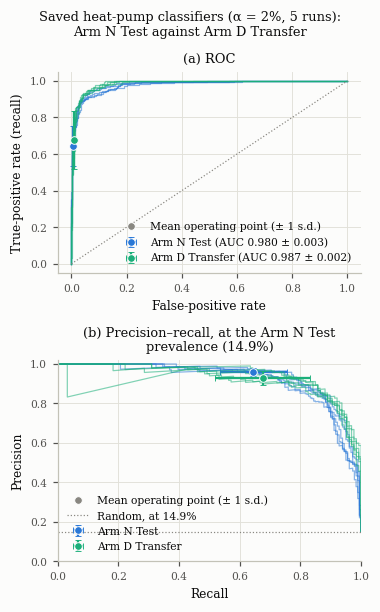

In [7]:
pi = PLOT_PREVALENCE   # Figure HP_T3 (section 8)
pi_pr = y_s.mean()     # panel (b): the Arm N Test prevalence
SETS = {"Arm N Test": (test, y_s, SET_COLOR["test"]),
        "Arm D Transfer": (tr, y_t, SET_COLOR["transfer"])}

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.6))
    for name, (df, y, col) in SETS.items():
        aucs, ops = [], []
        for seed in SEEDS:
            s = df[f"score_{seed}"].to_numpy()
            fpr_c, tpr_c, _ = roc_curve(y, s)
            aucs.append(roc_auc_score(y, s))
            with np.errstate(invalid="ignore", divide="ignore"):
                prec_pi = np.where(tpr_c > 0, tpr_c * pi_pr / (tpr_c * pi_pr + fpr_c * (1 - pi_pr)), 1.0)
            axes[0].plot(fpr_c, tpr_c, color=col, lw=0.8, alpha=0.55)
            axes[1].plot(tpr_c, prec_pi, color=col, lw=0.8, alpha=0.55)
            r, f = (s >= THR[seed])[y == 1].mean(), (s >= THR[seed])[y == 0].mean()
            ops.append((f, r, pc.restate(r, f, pi_pr)[0]))
        ops = np.array(ops)
        m, sd = ops.mean(axis=0), ops.std(axis=0, ddof=1)
        axes[0].errorbar(m[0], m[1], xerr=sd[0], yerr=sd[1], marker="o", color=col, ms=5, ls="none",
                         mec="white", mew=0.6, capsize=2,
                         label=f"{name} (AUC {np.mean(aucs):.3f} ± {np.std(aucs, ddof=1):.3f})")
        axes[1].errorbar(m[1], m[2], xerr=sd[1], yerr=sd[2], marker="o", color=col, ms=5, ls="none",
                         mec="white", mew=0.6, capsize=2, label=name)
    for ax in axes:
        ax.plot([], [], marker="o", color=INK_MUTED, ms=5, ls="none", mec="white", mew=0.6,
                label="Mean operating point (± 1 s.d.)")

    ax = axes[0]
    ax.plot([0, 1], [0, 1], color=INK_MUTED, lw=0.8, ls=":")
    ax.set_xlabel("False-positive rate")
    ax.set_ylabel("True-positive rate (recall)")
    ax.set_title("(a) ROC")
    ax.legend(loc="lower right", frameon=False)

    ax = axes[1]
    ax.axhline(pi_pr, color=INK_MUTED, lw=0.8, ls=":", label=f"Random, at {pi_pr:.1%}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_ylim(0, 1.02)
    ax.set_xlim(0, 1.0)
    ax.set_title(f"(b) Precision–recall, at the Arm N Test\nprevalence ({pi_pr:.1%})")
    ax.legend(loc="lower left", frameon=False)
    fig.suptitle("Saved heat-pump classifiers (α = 2%, 5 runs):\nArm N Test against Arm D Transfer",
                 fontsize=8.5)
    fig.tight_layout()
    savefig(fig, "HP_T1_roc_pr")
    plt.show()

## 7. Figure HP_T2 - Score distributions by label

Each household's score minus each run's threshold, averaged over the five runs, so 0 is the
threshold. Each panel compares the Arm N Test with the Arm D Transfer, for one label. A shift among
households without a heat pump points to the hosts (arm D and its tariff); a shift among heat-pump
households points to the heat pumps (OVO) as well.

saved -> figures/HP_T2_score_distributions.png


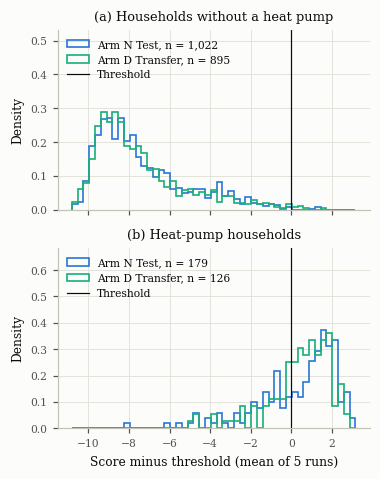

,Arm N Test,Arm D Transfer
"median score minus threshold, no heat pump",-7.968,-8.075
"median score minus threshold, heat pump",0.979,0.719


In [8]:
for df in (test, tr):
    df["margin"] = np.mean([df[f"score_{seed}"] - THR[seed] for seed in SEEDS], axis=0)
allm = np.r_[test.margin, tr.margin]
bins = np.linspace(allm.min(), allm.max(), 50)
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 4.4), sharex=True)
    for ax, lab, title in ((axes[0], 0, "(a) Households without a heat pump"),
                           (axes[1], 1, "(b) Heat-pump households")):
        for name, (df, y, col) in SETS.items():
            ax.hist(df.loc[y == lab, "margin"], bins=bins, density=True, histtype="step", lw=1.1,
                    color=col, label=f"{name}, n = {(y == lab).sum():,}")
        ax.axvline(0, color=INK_PRIMARY, lw=0.8, label="Threshold")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.75)
        ax.set_ylabel("Density")
        ax.set_title(title)
        ax.legend(loc="upper left", frameon=False)
    axes[1].set_xlabel("Score minus threshold (mean of 5 runs)")
    fig.tight_layout()
    savefig(fig, "HP_T2_score_distributions")
    plt.show()

shift = pd.DataFrame({name: {"median score minus threshold, no heat pump": df.loc[y == 0, "margin"].median(),
                             "median score minus threshold, heat pump": df.loc[y == 1, "margin"].median()}
                      for name, (df, y, _) in SETS.items()}).round(3)
shift

## 8. Figure HP_T3 - Confusion matrices per 1,000 households at 5% prevalence

As in Figure HP_PU5: the expected counts in 1,000 households of which 50 have a heat pump, from each
column's recall and false-positive rate, averaged over the five runs. True positives = 50 × recall;
false positives = 950 × false-positive rate.

saved -> figures/HP_T3_confusion_per_1000.png


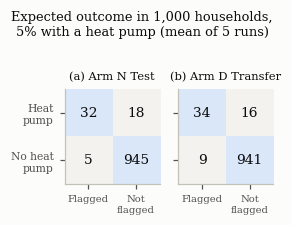

Arm N Test: 32 of 50 found, 5 false alarms
Arm D Transfer: 34 of 50 found, 9 false alarms


In [9]:
N_HH = 1000
ops = {"Arm N Test": runs["test"].mean(), "Arm D Transfer": runs["transfer"].mean()}
with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(1, 2, figsize=(COL_WIDTH * 0.75, 2.0))
    for ax, (name, v), tag in zip(axes, ops.items(), "ab"):
        r, fp = v["Recall"], v["False-positive rate"]
        npos, nneg = N_HH * pi, N_HH * (1 - pi)
        cm = np.array([[npos * r, npos * (1 - r)], [nneg * fp, nneg * (1 - fp)]])
        ax.imshow([[1, 0], [0, 1]], cmap=ListedColormap(["#f3f2ee", "#d9e7f8"]), vmin=0, vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=9,
                        color=INK_PRIMARY)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Flagged", "Not\nflagged"], fontsize=6.5)
        ax.set_yticks([0, 1])
        ax.set_yticklabels(["Heat\npump", "No heat\npump"] if tag == "a" else ["", ""])
        ax.grid(False)
        ax.set_title(f"({tag}) {name}", fontsize=7.5)
    fig.suptitle(f"Expected outcome in {N_HH:,} households,\n{pi:.0%} with a heat pump (mean of 5 runs)",
                 fontsize=8.5)
    fig.tight_layout()
    savefig(fig, "HP_T3_confusion_per_1000")
    plt.show()

for name, v in ops.items():
    print(f"{name}: {N_HH * pi * v['Recall']:.0f} of {N_HH * pi:.0f} found, "
          f"{N_HH * (1 - pi) * v['False-positive rate']:.0f} false alarms")

## 9. Notes and limitations

- The test applies all five α = 2% runs. The ± values are the spread over runs, not confidence
  intervals, and the households are fixed.
- Hosts and heat pumps change at the same time, so the shift can only partly be attributed to one
  or the other.
- OVO has few hybrids, the hardest type, so air source is the fair comparison; the other types are
  too few to read.
- The adjusted count assumes recall and the false-positive rate carry over from the Arm N Test,
  and it uses households without a heat pump, which a real deployment wouldn't have.
- The positives are still constructed, not real owners.